In [67]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")
include("../util_shoji.jl")


SOR (generic function with 1 method)

omega:1.9993718788097061
SOR converged: iteration = 26310
Maximum error = 1.0007295242822623e-7
L2 error       = 1.8764262741616222e-7


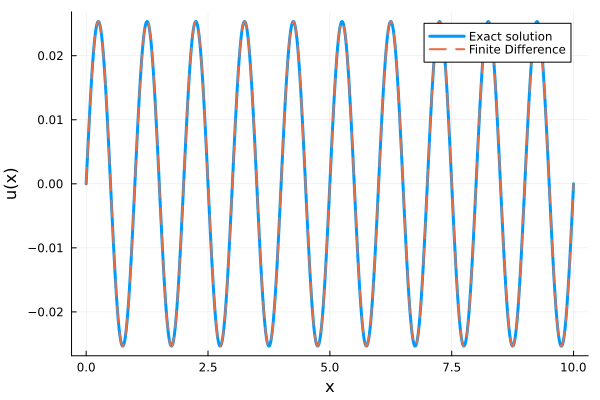

In [68]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.001
T = 10.0
x = 0:dt:T


xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# u'' =  - sin(2πx)
# -----------------------------
A = spzeros(n, n)

for i in 1:n
    A[i,i] = - 2.0
    if i > 1
        A[i,i-1] =  1.0
    end
    if i < n
        A[i,i+1] = 1.0
    end
end

A ./= (dt)^2

# Right-hand side
f =  - sin.(2π .* xi)

# Solve linear system
#u_interior = A \ f
omega = 2/(1 + sin(pi/(n+1)))
println("omega:", omega)
u_interior = SOR(A, f; omega = omega)

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = (1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [69]:




X_train = collect(0:dt:T)
y_train = -sin.(2π .* X_train)



#println("X_train:", X_train)
#println("y_train:", y_train)

#println(y_train.size)

 
#

10001-element Vector{Float64}:
 -0.0
 -0.006283143965558951
 -0.012566039883352607
 -0.018848439715408175
 -0.02513009544333748
 -0.03141075907812829
 -0.03769018266993454
 -0.0439681183178649
 -0.050244318179769556
 -0.05651853448202452
  ⋮
  0.050244318179768876
  0.04396811831786816
  0.037690182669941744
  0.03141075907813234
  0.025130095443338364
  0.018848439715413005
  0.01256603988336138
  0.006283143965557457
  2.4492935982947065e-15

In [70]:
#ℓ = best_ℓ
ℓ = 0.2
σf = 0.01
C = 0.01

l=1.0
σf=1.0
C=1.0


# -------------------------
# Test Points
# -------------------------
#X_test = collect(range(-5, 5, length=300))

X_test = collect(range(0, T, length=300))
# -------------------------
# Covariance Matrices
# -------------------------

#println("flag")

function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = spzeros(n-2, n)

    #for i in 1:n-2
    #    D[i,i+1] = 1
    #end

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = - 2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end




function observation_matrix(n, dt)

    D = laplacian_matrix(n, dt)

    H = spzeros(n, n)

    # u(0)
    H[1,1] = 1.0

    # Lu (internal)
    H[2:n-1, :] .= D

    # u(1)
    H[end,end] = 1.0

    return H
end

#println("flag")
H = observation_matrix(length(X_train), dt)


#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) +
#    σn^2 * I
#println("flag")

TrainK = kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf)

T = Tridiagonal(
    diag(TrainK, -1),
    diag(TrainK),
    diag(TrainK, 1)
)

#println("TrainK:", TrainK)
#println("T:", T)

K =
    H * T * H' +
#    H * TrainK * H' +
#    σn^2 * I
     C * (dt)^4 * I
#K +=  10e-6*I


#println("H * kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) * H':", H * kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) * H')

#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf)  +
#    σn^2 * I

#println("K.size:", K.size)
#println("K:", K)
#println("flag")

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

Ks = Tridiagonal(
    diag(Ks, -1),
    diag(Ks),
    diag(Ks, 1)
)


#println("Ks.size:", Ks.size)
#println("flag")
Ks = H * Ks
#println("flag")
Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

Kss = Tridiagonal(
    diag(Kss, -1),
    diag(Kss),
    diag(Kss, 1)
)

#println("Kss.size:", Kss.size)







ArgumentError: ArgumentError: cannot construct Tridiagonal from incompatible lengths of subdiagonal, diagonal and superdiagonal: (300, 300, 299)

In [64]:
# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)


#

300×300 Matrix{Float64}:
 -59.7467    -64.8473    -68.8199    …    1.25941     1.31449     1.33413
 -64.8473    -70.7439    -75.4977         1.24086     1.29513     1.31449
 -68.8199    -75.4977    -81.0592         1.18886     1.24086     1.25941
 -71.4419    -78.8506    -85.2133         1.10762     1.15607     1.17336
 -72.5755    -80.629     -87.7495         1.00345     1.04736     1.06304
 -72.1797    -80.7583    -88.5555    …    0.883998    0.922694    0.936512
 -70.3112    -79.2674    -87.6244         0.757265    0.790431    0.80228
 -67.1155    -76.2814    -85.0511         0.630785    0.65843     0.668316
 -62.8084    -72.0059    -81.0194         0.510906    0.533321    0.541346
 -57.6528    -66.7041    -75.7805         0.402358    0.420037    0.426378
   ⋮                                 ⋱                          
   0.541348    0.533323    0.510909     -81.0194    -72.0059    -62.8084
   0.668318    0.658432    0.630787     -85.0511    -76.2813    -67.1155
   0.802282    0.790

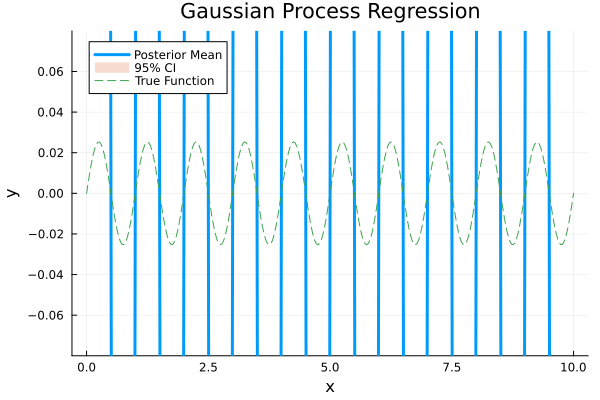

"/Users/shoji/Project_with_Jon/Poisson Equation/a.png"

In [65]:
#std =
#    sqrt.(diag(Σ))
std = sqrt.(max.(diag(Σ), 0.0))


#-------------------------
# Visualization
# -------------------------
plot(
    X_test,
    μ,
    label="Posterior Mean",
    lw=3
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=μ .- 1.96 .* std,
    fillalpha=0.25,
    linealpha=0,
    label="95% CI"
)

#scatter!(
#    X_train,
#    y_train,
#    label="Training Data",
#    ms=5
#)

plot!(
    X_test,
    #sin.(X_test),
    (1/(2π)^2) * sin.(2π .* X_test),
    ylims = (-0.08, 0.08),
    ls=:dash,
    label="True Function"
)

xlabel!("x")
ylabel!("y")
title!("Gaussian Process Regression")

display(current())

savefig("a.png")

In [94]:
function log_marginal_H(
    X_train,
    y;
    H,
    dt,
    ℓ,
    σf,
    C,
    prior_mean = 0.0
)

    K =
        H *
        kernel_matrix(X_train, X_train;
                      ℓ=ℓ,
                      σf=σf) *
        H' +
        C * (dt)^4 * I
    #K +=  10e-6*I


    m = fill(prior_mean, length(y))

    L = cholesky(Hermitian(K)).L
    α = L' \ (L \ (y - m))

    logdetK = 2sum(log.(diag(L)))

    

    return -0.5 * ((y - m)' * α) -
           0.5 * logdetK -
           0.5 * length(y) * log(2π)
end



log_marginal_H (generic function with 1 method)

In [95]:
ℓ_grid = [ 0.0001, 0.001,0.1,0.5,1.0,2.0,5.0,10.0,100.0, 1000]

σf_grid = [0.001,0.01,0.03,
           0.1,0.3,1.0,3.0,
           10.0,30.0,100.0,500.0, 1000.0, 10000.0]

C_grid = [1]

ℓ_grid  = 10 .^ range(-3, 3, length=5)
σf_grid = 10 .^ range(-3, 3, length=5)
C_grid  = 10 .^ range(-3, 3, length=5)

scores = zeros(length(ℓ_grid),
               length(σf_grid),
               length(C_grid))

for (i,ℓ) in enumerate(ℓ_grid)
    for (j,σf) in enumerate(σf_grid)
        for (k,C) in enumerate(C_grid)
            println("parameters:", ℓ, σf, C)

            scores[i,j,k] =
                log_marginal_H(
                    X_train,
                    y_train;
                    H=H,
                    dt=dt,
                    ℓ=ℓ,
                    σf=σf,
                    C=C,
                    prior_mean=0.0
                )

        end
    end
end

best_linear_idx = argmax(scores)
best_I = CartesianIndices(scores)[best_linear_idx]

best_ℓ  = ℓ_grid[best_I[1]]
best_σf = σf_grid[best_I[2]]
best_C  = C_grid[best_I[3]]
println("l=", best_ℓ)
println("σf=", best_σf)
println("C=", best_C)
best_loglik =
    log_marginal_H(
        X_train,
        y_train;
        H=H,
        dt=dt,
        ℓ=best_ℓ,
        σf=best_σf,
        C=best_C,
        prior_mean=0.0
    )

println("log marginal likelihood (best) = ", best_loglik)



parameters:0.0010.0010.001
parameters:0.0010.0010.03162277660168379
parameters:0.0010.0011.0
parameters:0.0010.00131.622776601683793
parameters:0.0010.0011000.0
parameters:0.0010.031622776601683790.001
parameters:0.0010.031622776601683790.03162277660168379
parameters:0.0010.031622776601683791.0
parameters:0.0010.0316227766016837931.622776601683793
parameters:0.0010.031622776601683791000.0
parameters:0.0011.00.001
parameters:0.0011.00.03162277660168379
parameters:0.0011.01.0
parameters:0.0011.031.622776601683793
parameters:0.0011.01000.0
parameters:0.00131.6227766016837930.001
parameters:0.00131.6227766016837930.03162277660168379
parameters:0.00131.6227766016837931.0
parameters:0.00131.62277660168379331.622776601683793
parameters:0.00131.6227766016837931000.0
parameters:0.0011000.00.001
parameters:0.0011000.00.03162277660168379
parameters:0.0011000.01.0
parameters:0.0011000.031.622776601683793
parameters:0.0011000.01000.0
parameters:0.031622776601683790.0010.001
parameters:0.03162277660

PosDefException: PosDefException: matrix is not positive definite; Factorization failed.

In [71]:
function bad_kernel(x1,x2; ℓ=1.0, cutoff=1.0)
    r = abs(x1-x2)
    if r > cutoff
        return 0.0
    else
        return exp(-r^2/(2ℓ^2))
    end
end


x = collect(0:0.2:5)

K = [bad_kernel(xi,xj) for xi in x, xj in x]

eigvals(Symmetric(K))

26-element Vector{Float64}:
 -1.1320212739871378
 -0.9995934512848994
 -0.6391783110818425
 -0.5674719087100345
 -0.4883202006531192
 -0.4509033470561352
 -0.32600001799858747
 -0.24854374816773653
 -0.20306088025704233
 -0.11726435193318194
  ⋮
  0.4841535354247956
  0.6345490085617745
  0.6534942812762902
  0.7769133918289811
  1.9142005145509469
  3.7118192633950513
  5.711179875609034
  7.376456644498131
  8.603183378314295